# This Project is intended to look at CO2 emissions data for countries with a greater then 10m population and explore how the countries have decreased or increased their CO2 emissions per capita. We then explore the reasonings that caused said increase or decrease and see if any countries have made conscious efforts to lower CO2 emissions.

In [38]:
#Importing the packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [39]:
#Importing the data

co2 = pd.read_csv("https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv")

# Visualizing the data

In [40]:
#Visualizing the data
co2.head()

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
#looking at the above seems like the data set has a lot of nulls, looks like data in Afghanistan may be limited. It does
#look like the data spans a few years however it may not make sense to look at all of this. we will want to do 
#some cleanup here. 

#Looking to also see how many rows exist
co2.shape

(50411, 79)

In [42]:
#Getting a feel for what the columns look like.  
co2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50411 entries, 0 to 50410
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    50411 non-null  object 
 1   year                                       50411 non-null  int64  
 2   iso_code                                   42480 non-null  object 
 3   population                                 41167 non-null  float64
 4   gdp                                        15251 non-null  float64
 5   cement_co2                                 29173 non-null  float64
 6   cement_co2_per_capita                      25648 non-null  float64
 7   co2                                        29384 non-null  float64
 8   co2_growth_abs                             27216 non-null  float64
 9   co2_growth_prct                            26239 non-null  float64
 10  co2_including_luc     

In [43]:
### Data is patchy based on the above, seems like we have sum nulls in the IDO code, investigating that. 
#How many of the items are null?
co2['iso_code'].isna().sum()

7931

In [44]:
#checking to see which values these are.
co2[co2['iso_code'].isna()]['country'].unique()

array(['Africa', 'Africa (GCP)', 'Asia', 'Asia (GCP)',
       'Asia (excl. China and India)', 'Central America (GCP)', 'Europe',
       'Europe (GCP)', 'Europe (excl. EU-27)', 'Europe (excl. EU-28)',
       'European Union (27)', 'European Union (28)',
       'High-income countries', 'International aviation',
       'International shipping', 'Kosovo', 'Kuwaiti Oil Fires',
       'Kuwaiti Oil Fires (GCP)',
       'Least developed countries (Jones et al.)', 'Low-income countries',
       'Lower-middle-income countries', 'Middle East (GCP)',
       'Non-OECD (GCP)', 'North America', 'North America (GCP)',
       'North America (excl. USA)', 'OECD (GCP)', 'OECD (Jones et al.)',
       'Oceania', 'Oceania (GCP)', 'Ryukyu Islands',
       'Ryukyu Islands (GCP)', 'South America', 'South America (GCP)',
       'Upper-middle-income countries', 'World'], dtype=object)

In [45]:
#look weird,it looks ike the country column has some non-countries.visualizing this.
co2[co2['iso_code'].isna()].head(25)

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
275,Africa,1750,NaN,79382032.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276,Africa,1751,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
277,Africa,1752,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
278,Africa,1753,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
279,Africa,1754,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
280,Africa,1755,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
281,Africa,1756,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
282,Africa,1757,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
283,Africa,1758,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
284,Africa,1759,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


looks like the country column has some non- countries, this is something to watch out for. That being said, Kosovo
is also there which is a disputed country, We will keep Kosovo for this project.

In [46]:
## looks like we are looking at several years data for the different countires, it makes sense to see which year we 
#are looking at. 

co2['year'].min()


1750

In [47]:
co2['year'].max()

2024

# Data cleaning

In [48]:
# Explicit exclusion list — aggregates and non-country entities, built from eyeballing the array AND 
#checking which ones still have real data. Kosovo is deliberately NOT in this list — it's a real country, just
# missing an ISO code for political reasons, not a data gap.

#creating a list of actual non-countries
non_countries = [
    'Africa', 'Africa (GCP)', 'Asia', 'Asia (GCP)',
    'Asia (excl. China and India)', 'Central America (GCP)', 'Europe',
    'Europe (GCP)', 'Europe (excl. EU-27)', 'Europe (excl. EU-28)',
    'European Union (27)', 'European Union (28)', 'High-income countries',
    'International aviation', 'International shipping',
    'Kuwaiti Oil Fires', 'Kuwaiti Oil Fires (GCP)',
    'Least developed countries (Jones et al.)', 'Low-income countries',
    'Lower-middle-income countries', 'Middle East (GCP)', 'Non-OECD (GCP)',
    'North America', 'North America (GCP)', 'North America (excl. USA)',
    'OECD (GCP)', 'OECD (Jones et al.)', 'Oceania', 'Oceania (GCP)',
    'Ryukyu Islands', 'Ryukyu Islands (GCP)', 'South America (GCP)',
    'Upper-middle-income countries', 'World','South America'
]

#Removing the non countries
co2_countries = co2[~co2['country'].isin(non_countries)].copy()

#Also limiting the years we look at since its no use to look at the 18th century
co2_recent = co2_countries[co2_countries['year'] >= 1990].copy()

#Just checkign how many countries we have
print(co2_recent['country'].nunique())


219


In [49]:
#From our now filtered data, without non-countries finsing out how many nulls we have, looks like we stil 
#have a few will have to be careful
print(co2_recent['co2_per_capita'].isna().sum(), "nulls out of", len(co2_recent))

192 nulls out of 7665


## We will do some analysis now on our cleaned data set. we will evenutally compare the countries' latest omissions numbers with the 2015 date then we will also take a look at what the countries highest omission rate was in our timeframe of after 1990. First we compare the current CO2 emission against the countries most recent

In [50]:
#First we get the highest of the CO2_per_capita per country and then return the columns for it
peak_idx = co2_recent.dropna(subset=['co2_per_capita']).groupby('country')['co2_per_capita'].idxmax()
peak = co2_recent.loc[peak_idx, ['country', 'year', 'co2_per_capita']].rename(
    columns={'year': 'peak_year', 'co2_per_capita': 'peak_value'}
)

# creating a table to compute each country's most recent *available* value — not necessarily 2024,
# since some countries lag in reporting and their last real number might be from an earlier year
latest = (
    co2_recent.dropna(subset=['co2_per_capita'])
    .sort_values('year')
    .groupby('country')
    .tail(1)[['country', 'year', 'co2_per_capita']]
    .rename(columns={'year': 'latest_year', 'co2_per_capita': 'latest_value'})
)

#creating a table to compare the two databases. adding in columns to compute the absolute and pct changes
peak_vs_latest = peak.merge(latest, on='country')
peak_vs_latest['abs_change'] = peak_vs_latest['latest_value'] - peak_vs_latest['peak_value']
peak_vs_latest['pct_change'] = peak_vs_latest['abs_change'] / peak_vs_latest['peak_value'] * 100

In [51]:
peak_vs_latest

,country,peak_year,peak_value,latest_year,latest_value,abs_change,pct_change
0,Afghanistan,2011,0.389,2024,0.254,-0.135,-34.704370
1,Albania,2014,2.091,2024,1.592,-0.499,-23.864180
2,Algeria,2023,4.394,2024,4.234,-0.160,-3.641329
3,Andorra,2002,7.986,2024,5.182,-2.804,-35.111445
4,Angola,1999,1.102,2024,0.589,-0.513,-46.551724
...,...,...,...,...,...,...,...
209,Vietnam,2020,3.697,2024,3.673,-0.024,-0.649175
210,Wallis and Futuna,2024,2.699,2024,2.699,0.000,0.000000
211,Yemen,2009,1.037,2024,0.249,-0.788,-75.988428
212,Zambia,2023,0.571,2024,0.565,-0.006,-1.050788


## Next we will find the populations of this country to eventualy looks at CO2 emissions per capita in the spirit of being fair

In [52]:
#Next we add the latest populations for the country
#Finding the latest population data for each country
latest_pop = (
    co2_recent.dropna(subset=['population'])
    .sort_values('year')
    .groupby('country')
    .tail(1)[['country', 'population']]
)

#Adding in the latest_Pop column to our ranked table
ranked = peak_vs_latest.merge(latest_pop, on='country')

#Here we are dropping any countries that have a population <= 10 mil. The idea here is that these countries will be
#hard to analyze and that due to thier small poppulations, the smallest change will lead to a radical increase in the per
#capita co2 omission which will not meaningfully contribute to the gloabal CO2 omission thus just adding noise to the data.
#By only focusiing on so called Major countries we acna do a more meaningful analysis.There is a slight risk here that we
#may ignore a small country with a big impoct on the global CO2 so I will be looking at that seperately a bit later. 
major = ranked[ranked['population'] > 10_000_000].copy()

In [53]:
# Validating the population floor: do "minor" (population <= 10M) countries meaningfully contribute to global CO2, 
#or is the floor safe to use?

#We find the latest Co2 levels from country because we want to poppulate the contributuion of the country based on 
#its absolute Co2 emissions to the world(Not using co2/capita) once again we rely on finding the latest reported. 
latest_co2 = (
    co2_recent.dropna(subset=['co2'])
    .sort_values('year')
    .groupby('country')
    .tail(1)[['country', 'co2']]
)

#defineing the Is.major variable witht he countries defined previously
is_major = latest_co2['country'].isin(major['country'])

#Getting the Major and minot totals
major_total = latest_co2.loc[is_major, 'co2'].sum()
minor_total = latest_co2.loc[~is_major, 'co2'].sum()

#printing them to convince ourselves
print(f"Major: {major_total:,.0f} Mt ({100*major_total/(major_total+minor_total):.1f}%)")
print(f"Minor: {minor_total:,.0f} Mt ({100*minor_total/(major_total+minor_total):.1f}%)")

#Creating a column to display the value as the total percentage compared to the world
world_total = major_total + minor_total
latest_co2['pct_of_world'] = latest_co2['co2'] / world_total * 100

latest_co2[~is_major].sort_values('co2', ascending=False).head(10)

Major: 35,850 Mt (95.8%)
Minor: 1,556 Mt (4.2%)


,country,co2,pct_of_world
24865,Kuwait,129.519,0.346251
37960,Qatar,125.812,0.336341
35885,Oman,82.662,0.220985
46428,Turkmenistan,81.006,0.216558
26479,Libya,65.260,0.174463
3885,Austria,56.368,0.150692
5243,Belarus,55.818,0.149222
41364,Singapore,53.919,0.144145
23187,Israel,52.637,0.140718
30562,Mongolia,44.694,0.119483


The total above just confirms that the countries left out only acvcount for <5% of the worlds total emissions. Kuwait, QAtar and Oman do contirbute a adecent amount but their contributiion is explained by the oild based economies thye are. 

In [54]:
#Now we want to build a column with the countries 2015 data to compare this to the latest data. 

# First lets make sure that all our Major countries actualy have the data for 2015, if not we m,ay have to thing of another way to do this. 
baseline_year = 2015

# Constuct a table with all countries in out co2_recenmt data set that have data in the 2015 data
baseline = co2_recent[(co2_recent['year'] == baseline_year) & co2_recent['co2_per_capita'].notna()][['country', 'co2_per_capita']].rename(columns={'co2_per_capita': 'baseline_2015_value'})

#We do a in major but not in baseline chaeck byt addeing the merge column and counting to see if any of the mege is left only 
check = major.merge(baseline, on='country', how='left', indicator=True)
missing_2015 = check[check['_merge'] == 'left_only']

#Below code confirms that no country in our major data set is missing 2015 data
print(len(missing_2015), "major countries missing a 2015 value:", missing_2015['country'].tolist())



0 major countries missing a 2015 value: []


In [55]:
#Next we will add the absolute and percent changes for 2015 to our peak_cs_latest table
trend = peak_vs_latest.merge(baseline, on='country')
trend['change_since_2015'] = trend['latest_value'] - trend['baseline_2015_value']
trend['pct_change_since_2015'] = trend['change_since_2015'] / trend['baseline_2015_value'] * 100


In [56]:
#Adding in the trend column for 2015 on the major table
major = major.merge(
    trend[['country', 'baseline_2015_value', 'change_since_2015', 'pct_change_since_2015']],
    on='country'
)

In [57]:
major

,country,peak_year,peak_value,latest_year,latest_value,abs_change,pct_change,population,baseline_2015_value,change_since_2015,pct_change_since_2015
0,Afghanistan,2011,0.389,2024,0.254,-0.135,-34.704370,42647502.0,0.277,-0.023,-8.303249
1,Algeria,2023,4.394,2024,4.234,-0.160,-3.641329,46814302.0,4.006,0.228,5.691463
2,Angola,1999,1.102,2024,0.589,-0.513,-46.551724,37885854.0,0.977,-0.388,-39.713408
3,Argentina,2008,4.641,2024,3.743,-0.898,-19.349278,45696153.0,4.412,-0.669,-15.163191
4,Australia,2004,19.056,2024,14.477,-4.579,-24.029177,26713206.0,16.727,-2.250,-13.451306
...,...,...,...,...,...,...,...,...,...,...,...
90,Venezuela,2013,6.634,2024,4.085,-2.549,-38.423274,28405544.0,5.440,-1.355,-24.908088
91,Vietnam,2020,3.697,2024,3.673,-0.024,-0.649175,100987685.0,2.299,1.374,59.765115
92,Yemen,2009,1.037,2024,0.249,-0.788,-75.988428,40583173.0,0.453,-0.204,-45.033113
93,Zambia,2023,0.571,2024,0.565,-0.006,-1.050788,21314962.0,0.337,0.228,67.655786


In [58]:
#Lookiing at the top decliners and risers in terms of percentage change of CO2 emissions between 2015 and the latest data
top_decliners = major.sort_values('pct_change_since_2015').head(10)
top_risers = major.sort_values('pct_change_since_2015', ascending=False).head(10)

In [59]:
top_decliners

,country,peak_year,peak_value,latest_year,latest_value,abs_change,pct_change,population,baseline_2015_value,change_since_2015,pct_change_since_2015
92,Yemen,2009,1.037,2024,0.249,-0.788,-75.988428,40583173.0,0.453,-0.204,-45.033113
2,Angola,1999,1.102,2024,0.589,-0.513,-46.551724,37885854.0,0.977,-0.388,-39.713408
54,Netherlands,1996,11.671,2024,6.297,-5.374,-46.045754,18228740.0,9.584,-3.287,-34.296745
63,Portugal,2002,6.682,2024,3.409,-3.273,-48.982341,10425291.0,5.037,-1.628,-32.320826
29,Germany,1990,13.233,2024,6.769,-6.464,-48.847578,84552234.0,9.757,-2.988,-30.624167
87,United Kingdom,1991,10.588,2024,4.526,-6.062,-57.253495,69138185.0,6.461,-1.935,-29.948924
22,Czechia,1990,15.944,2024,7.044,-8.900,-55.820371,10735857.0,9.976,-2.932,-29.390537
42,Jordan,2005,3.448,2024,2.010,-1.438,-41.705336,11552885.0,2.703,-0.693,-25.638180
90,Venezuela,2013,6.634,2024,4.085,-2.549,-38.423274,28405544.0,5.440,-1.355,-24.908088
14,Cameroon,2009,0.448,2024,0.331,-0.117,-26.116071,29123748.0,0.433,-0.102,-23.556582


In [60]:
top_risers

,country,peak_year,peak_value,latest_year,latest_value,abs_change,pct_change,population,baseline_2015_value,change_since_2015,pct_change_since_2015
53,Nepal,2024,0.633,2024,0.633,0.000,0.000000,29651054.0,0.248,0.385,155.241935
13,Cambodia,2020,1.255,2024,1.241,-0.014,-1.115538,17638804.0,0.524,0.717,136.832061
12,Burundi,2022,0.066,2024,0.065,-0.001,-1.515152,14047788.0,0.032,0.033,103.125000
57,North Korea,1990,5.607,2024,2.360,-3.247,-57.909756,26498832.0,1.223,1.137,92.968111
66,Rwanda,2023,0.144,2024,0.143,-0.001,-0.694444,14256573.0,0.083,0.060,72.289157
93,Zambia,2023,0.571,2024,0.565,-0.006,-1.050788,21314962.0,0.337,0.228,67.655786
79,Tajikistan,1990,2.280,2024,1.014,-1.266,-55.526316,10590930.0,0.614,0.400,65.146580
91,Vietnam,2020,3.697,2024,3.673,-0.024,-0.649175,100987685.0,2.299,1.374,59.765115
48,Mali,2021,0.330,2024,0.285,-0.045,-13.636364,24478597.0,0.183,0.102,55.737705
61,Philippines,2024,1.510,2024,1.510,0.000,0.000000,115843663.0,1.054,0.456,43.263757


# We wil graph the top 3 of each decliners and risers and investigate the cause for their rise or decline.

In [61]:
%matplotlib inline

['Yemen', 'Angola', 'Netherlands', 'Nepal', 'Cambodia', 'Burundi']


C:\Users\haroo\Anaconda3\lib\site-packages\matplotlib\cbook\__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
C:\Users\haroo\Anaconda3\lib\site-packages\matplotlib\axes\_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
C:\Users\haroo\Anaconda3\lib\site-packages\matplotlib\axes\_base.py:278: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  y = y[:, np.newaxis]


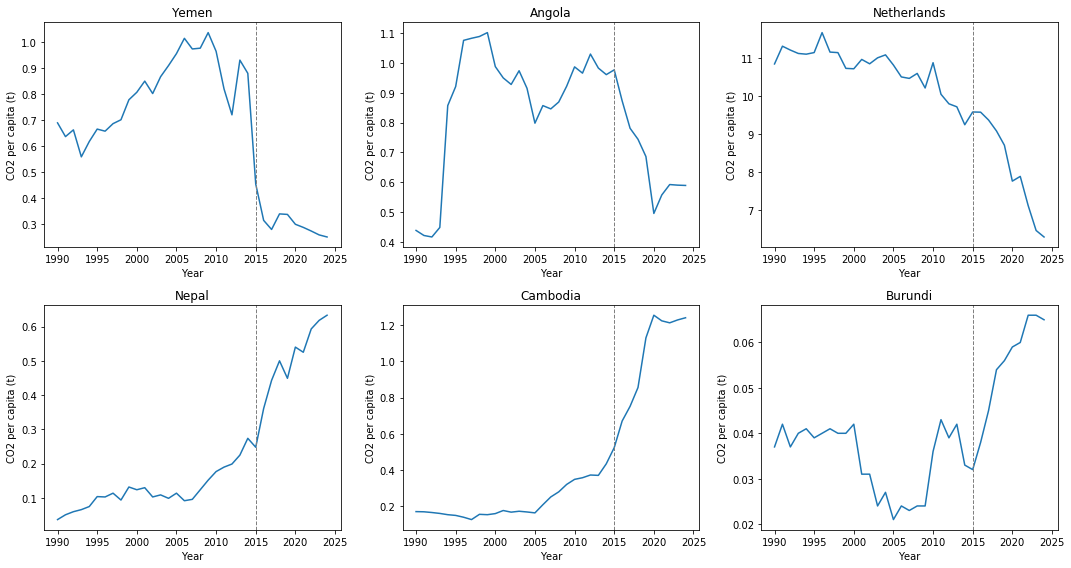

In [62]:
#We will plot the graphs for the top 3 risers and decliners. 

countries_to_check = top_decliners['country'].head(3).tolist() + top_risers['country'].head(3).tolist()
print(countries_to_check)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, country in zip(axes, countries_to_check):
    subset = co2_recent[co2_recent['country'] == country].sort_values('year')
    ax.plot(subset['year'], subset['co2_per_capita'])
    ax.axvline(2015, color='gray', linestyle='--', linewidth=1)
    ax.set_title(country)
    ax.set_xlabel('Year')
    ax.set_ylabel('CO2 per capita (t)')

plt.tight_layout()
plt.show()

We now turn to claude to understand what may be happening with these countries. For the most part it look like either
the rise or fall of co2 emissions are parts of trends preceeding 2015. 

Top 3 decliners:
    Yemen:Yemen’s decline predates the widely-known 2015 war. Its main oil export pipeline was repeatedly sabotaged during a fragile post-2011 political transition (2012–2014), crushing oil revenue before the 2014 Houthi takeover or the 2015 Saudi-led intervention. This is state and economic collapse, not decarbonization.
    Angola: Angola’s decline tracks the 2014 global oil price crash, not clean-energy policy. As a heavily oil-dependent economy, falling prices plus declining production from aging, underinvested fields drove a prolonged recession and a 2018 IMF support program. The 2020 dip reflects COVID’s oil demand collapse layered on top.
    Netherlands: Netherlands shows genuine decoupling, not crisis. Driven by the 2019 Urgenda Supreme Court climate ruling (legally binding emissions cuts), a 2030 coal phase-out, and the 2023 closure of the Groningen gas field.
    
Top 3 risers: 
    Nepal: Nepal’s real inflection is 2008, not earlier — flat/noisy through 2007. Matches the end of its civil war (2006) and the 2008 transition to a republic. What followed: remittances surged from 13.8% to 22% of GDP (FY07-FY09, World Bank), funding a construction boom that’s driven steady emissions growth since. Still among the world’s lowest absolute levels.
    Cambodia:Cambodia’s rise has two layers: broad economic growth (garment exports since 2004 WTO accession, Chinese-investment construction boom in Sihanoukville) plus a sharp 2018-2020 jump from a specific energy decision — Cambodia rapidly built coal/thermal power plants after 2019 blackouts, when demand outpaced a hydropower buildout delayed by a decade. Coal+heavy fuel oil jumped from under a third to over half of generation within about a year.
    Burundi: Burundi’s “+103% since 2015” is partly an artifact of the baseline year itself: 2015 was a genuine crisis year (a failed coup, mass violence, and an aid suspension following President Nkurunziza’s contested third-term bid), making it an unusually low reference point for this country specifically
    
    

In [63]:
#The above statment regarding the top risers contributing little to the overall CO2 
check_countries = ['Nepal', 'Cambodia', 'Burundi']
latest_co2[latest_co2['country'].isin(check_countries)][['country', 'co2', 'pct_of_world']]

,country,co2,pct_of_world
8187,Burundi,0.917,0.002451
8462,Cambodia,21.883,0.058501
31961,Nepal,18.776,0.050195


# From the countries that we have analyzed unfortunately it does not look like for most of them the decrease in CO2 emissions is a result of policies targeted to reduce pollution. Merely looking at the numbers of the countries is not enough to conclude that the countries that are declining are making concentrated efforts to reduce their carbon footprints.

# For the countries with increasing CO2 emissions, it seems like the increase is a natural one with regard to these countries developing, one thing to check is if the countries our analysis caught actually have meaningful contributions to the global CO2 emissions.  



In [64]:
#The above statment regarding the top risers contributing little to the overall co2 emission of the world was an educated guess
#below is the confirmaiton. it shows that all these couintries impact global nmumbers very little. 
check_countries = ['Nepal', 'Cambodia', 'Burundi']
latest_co2[latest_co2['country'].isin(check_countries)][['country', 'co2', 'pct_of_world']]

,country,co2,pct_of_world
8187,Burundi,0.917,0.002451
8462,Cambodia,21.883,0.058501
31961,Nepal,18.776,0.050195


# The above confirms that our top risers do not contribute meaningfully to the global emissions, a future analysis of this project will floor the minimum contribution a country has to the global emissions and then pick the top risers form that and then we will see what efforts if any are being done by those countries to limit their CO2 emission.

In [70]:
major = major.merge(latest_co2[['country', 'pct_of_world']], on='country')

In [71]:
top_decliner_names = top_decliners['country'].head(3).tolist()
top_riser_names = top_risers['country'].head(3).tolist()

def assign_group(country):
    if country in top_decliner_names:
        return 'decliner'
    elif country in top_riser_names:
        return 'riser'
    else:
        return 'other'

major['group'] = major['country'].apply(assign_group)

context = major[major['group'] == 'other']
highlighted = major[major['group'] != 'other']
colors = {'decliner': '#2a78d6', 'riser': '#e34948'}

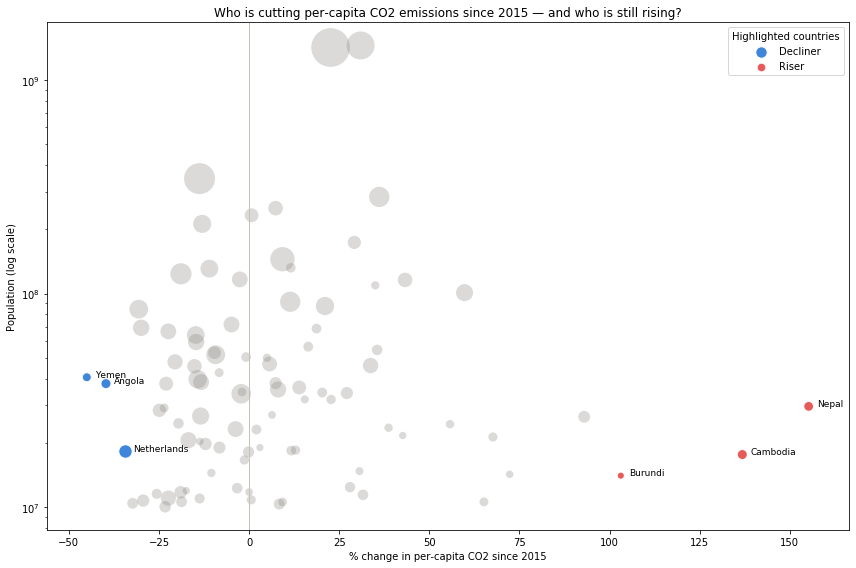

In [72]:
sqrt_vals = np.sqrt(major['pct_of_world'])
sqrt_min, sqrt_max = sqrt_vals.min(), sqrt_vals.max()

def scaled_size(values, min_size=50, max_size=1500):
    sqrt_values = np.sqrt(values)
    normalized = (sqrt_values - sqrt_min) / (sqrt_max - sqrt_min)
    return min_size + normalized * (max_size - min_size)

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    context['pct_change_since_2015'],
    context['population'],
    s=scaled_size(context['pct_of_world']),
    color='#898781',
    alpha=0.3,
    edgecolors='none'
)

for group, color in colors.items():
    subset = highlighted[highlighted['group'] == group]
    ax.scatter(
        subset['pct_change_since_2015'],
        subset['population'],
        s=scaled_size(subset['pct_of_world']),
        color=color,
        alpha=0.9,
        edgecolors='white',
        linewidths=1,
        label=group.capitalize()
    )
    for _, row in subset.iterrows():
        ax.annotate(row['country'], (row['pct_change_since_2015'], row['population']),
                    textcoords="offset points", xytext=(8, 0), fontsize=9)

ax.axvline(0, color='#c3c2b7', linewidth=1)
ax.set_yscale('log')
ax.set_xlabel('% change in per-capita CO2 since 2015')
ax.set_ylabel('Population (log scale)')
ax.set_title('Who is cutting per-capita CO2 emissions since 2015 — and who is still rising?')
ax.legend(title='Highlighted countries')

plt.tight_layout()
plt.show()

In [75]:
plt.savefig('hero_chart.png', dpi=150, bbox_inches='tight')

<Figure size 432x288 with 0 Axes>

In [76]:
import os
os.getcwd()

'C:\\Users\\haroo\\Claude sessions'